# 05 – PCA & K-Means: phân cụm phim IMDb

**Mục tiêu**
1. Chuẩn hóa các đặc trưng phù hợp (số liên tục → `StandardScaler`, danh mục → one-hot).
2. Dùng PCA giảm chiều và phân tích phương sai giải thích.
3. Chọn số cụm K bằng **Elbow** và **Silhouette Score**.
4. Chạy K-Means **có PCA** và **không có PCA**, so sánh hai phương án.
5. Vẽ biểu đồ cụm và giải thích đặc điểm từng nhóm phim.

**Đầu ra:** các mô hình trong `models/clustering/` (scaler, PCA, K-Means, bảng gán cụm, hình vẽ).

In [22]:
import warnings, time, json, glob, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib.ticker import MaxNLocator
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

# Cấu hình dùng chung
SEED = 42
OUT_DIR = os.path.join('models', 'clustering')
os.makedirs(OUT_DIR, exist_ok=True)

def savefig(filename):
    """Lưu biểu đồ vào thư mục output; vẫn hiển thị trong notebook."""
    plt.savefig(os.path.join(OUT_DIR, filename), dpi=150, bbox_inches='tight')


## 1. Nạp dữ liệu
Ba file IMDb có cùng ý nghĩa cột (file 3 có thêm `Second_Genre`, `Third_Genre`), nên được gộp lại thành một bảng. Cột `Poster-src` (link ảnh) không có giá trị phân cụm nên bị loại.

In [ ]:
df1 = pd.read_csv("C:\\Users\\ASUS TUF\\Downloads\\datanhom\\IMDb_Dataset.csv")
df2 = pd.read_csv("C:\\Users\\ASUS TUF\\Downloads\\datanhom\\IMDb_Dataset_2.csv")
df3 = pd.read_csv("C:\\Users\\ASUS TUF\\Downloads\\datanhom\\IMDb_Dataset_3.csv")
df = pd.concat([df1, df2, df3], ignore_index=True)
df = df.drop(columns=['Poster-src', 'Second_Genre', 'Third_Genre'])

## 2. Khám phá nhanh

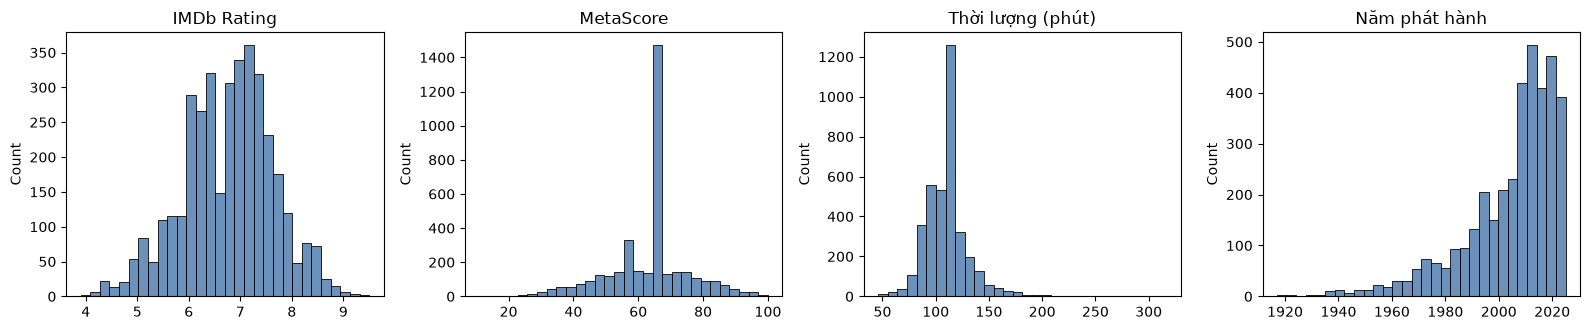

Độ lệch (skewness):
rating      -0.19
metascore   -0.40
duration     1.55
year        -1.48


In [25]:
num_cols = ['rating', 'metascore', 'duration', 'year']
labels_vi = {'rating': 'IMDb Rating', 'metascore': 'MetaScore', 'duration': 'Thời lượng (phút)', 'year': 'Năm phát hành'}
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a, c in zip(ax, num_cols):
    sns.histplot(df[c], bins=30, ax=a, color='#3b6ea5'); a.set_title(labels_vi[c]); a.set_xlabel('')
plt.tight_layout(); savefig('01_phan_phoi_so.png'); plt.show()
print('Độ lệch (skewness):'); print(df[num_cols].skew().round(2).to_string())

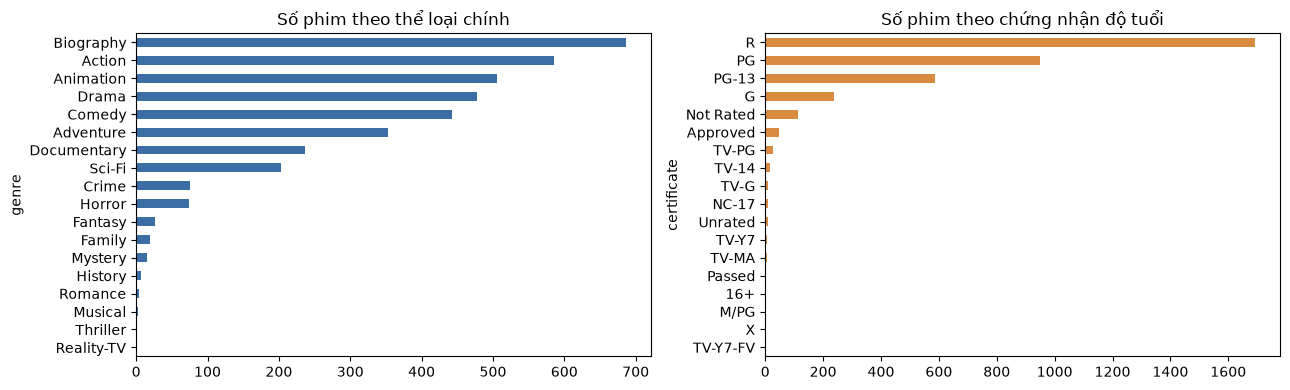

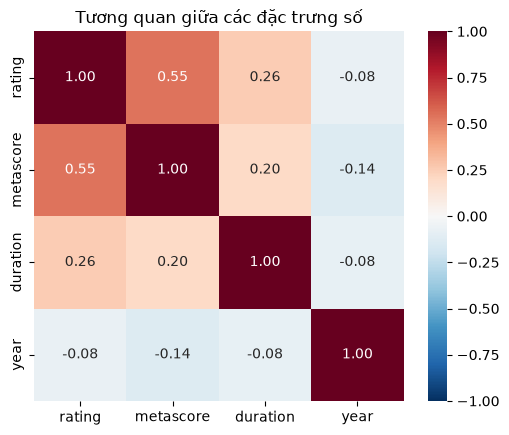

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df['genre'].value_counts().plot.barh(ax=ax[0], color='#3b6ea5'); ax[0].invert_yaxis(); ax[0].set_title('Số phim theo thể loại chính')
df['certificate'].value_counts().plot.barh(ax=ax[1], color='#d98c3f'); ax[1].invert_yaxis(); ax[1].set_title('Số phim theo chứng nhận độ tuổi')
plt.tight_layout(); savefig('02_the_loai_chung_nhan.png'); plt.show()
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Tương quan giữa các đặc trưng số'); savefig('03_tuong_quan.png'); plt.show()

## 3. Xây dựng và chuẩn hóa đặc trưng

| Nhóm | Cột | Xử lý |
|---|---|---|
| Số liên tục | `rating`, `metascore`, `duration`, `year` | `StandardScaler` (mean = 0, std = 1) để thang đo khác nhau (năm ~2000, rating ~7) không lấn át nhau |
| Danh mục | `genre` | Gộp thể loại hiếm (< 1,5 % số phim) vào `Other`, rồi one-hot |
| Danh mục | `certificate` | Gom về R / PG-13 / PG / G / Other, rồi one-hot |

Cột nhị phân one-hot đã nằm trong thang 0–1 nên được giữ nguyên, không scale thêm (nếu scale, thể loại hiếm sẽ bị phóng đại).

In [27]:
# --- gom chứng nhận ---
cert_map = {'R': 'R', 'PG-13': 'PG-13', 'PG': 'PG', 'G': 'G'}
df['cert_grp'] = df['certificate'].map(cert_map).fillna('Other')

# --- gom thể loại hiếm ---
share = df['genre'].value_counts(normalize=True)
keep = share[share >= 0.015].index
df['genre_grp'] = np.where(df['genre'].isin(keep), df['genre'], 'Other')
print('Thể loại giữ lại:', list(keep)); print('Chứng nhận:', df['cert_grp'].value_counts().to_dict())

X_cat = pd.get_dummies(df[['genre_grp', 'cert_grp']], prefix=['g', 'c']).astype(float)
cat_cols = list(X_cat.columns)

scaler = StandardScaler()
X_num = pd.DataFrame(scaler.fit_transform(df[num_cols]), columns=num_cols, index=df.index)
X = pd.concat([X_num, X_cat], axis=1)
feature_names = list(X.columns)
print(f'\nMa trận đặc trưng: {X.shape[0]} phim x {X.shape[1]} đặc trưng ({len(num_cols)} số + {len(cat_cols)} one-hot)')
X.describe().loc[['mean', 'std']].round(2).T.head(8)

Thể loại giữ lại: ['Biography', 'Action', 'Animation', 'Drama', 'Comedy', 'Adventure', 'Documentary', 'Sci-Fi', 'Crime', 'Horror']
Chứng nhận: {'R': 1694, 'PG': 950, 'PG-13': 588, 'Other': 250, 'G': 236}

Ma trận đặc trưng: 3718 phim x 20 đặc trưng (4 số + 16 one-hot)


,mean,std
rating,0.00,1.00
metascore,-0.00,1.00
duration,-0.00,1.00
year,0.00,1.00
g_Action,0.16,0.36
g_Adventure,0.09,0.29
g_Animation,0.14,0.34
g_Biography,0.18,0.39


## 1. PCA – giảm chiều và phương sai giải thích
Chạy PCA với đầy đủ thành phần để xem phương sai mỗi thành phần giải thích, sau đó chọn số thành phần dựa trên: (a) ngưỡng **phương sai tích lũy ≥ 90 %**, (b) điểm gấp khúc của **scree plot**.

Cần  6 thành phần để giữ >= 80% phương sai
Cần  9 thành phần để giữ >= 90% phương sai
Cần 12 thành phần để giữ >= 95% phương sai


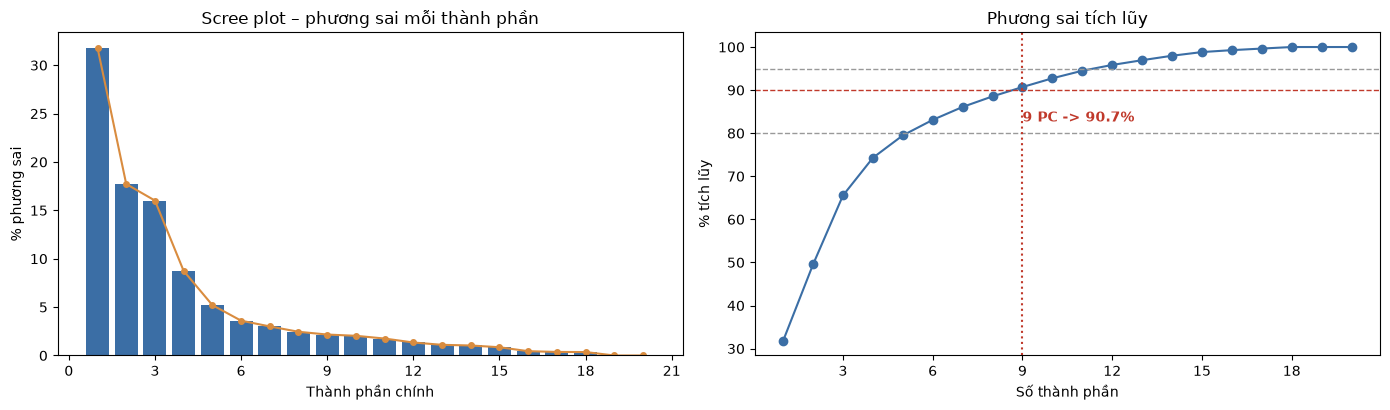

==> Chọn N_PC = 9 (phương sai giữ lại 90.7%)


In [28]:
pca_full = PCA(random_state=SEED).fit(X)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
for t in (0.80, 0.90, 0.95):
    print(f'Cần {np.argmax(cum >= t) + 1:2d} thành phần để giữ >= {t:.0%} phương sai')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
k = np.arange(1, len(evr) + 1)
ax[0].bar(k, evr * 100, color='#3b6ea5'); ax[0].plot(k, evr * 100, 'o-', color='#d98c3f', ms=4)
ax[0].set_title('Scree plot – phương sai mỗi thành phần'); ax[0].set_xlabel('Thành phần chính'); ax[0].set_ylabel('% phương sai')
ax[1].plot(k, cum * 100, 'o-', color='#3b6ea5')
for t, c in ((80, '#999'), (90, '#c0392b'), (95, '#999')):
    ax[1].axhline(t, ls='--', color=c, lw=1)
N_PC = int(np.argmax(cum >= 0.90) + 1)
ax[1].axvline(N_PC, ls=':', color='#c0392b'); ax[1].annotate(f'{N_PC} PC -> {cum[N_PC-1]:.1%}', (N_PC, cum[N_PC-1]*100-8), color='#c0392b', fontweight='bold')
ax[0].xaxis.set_major_locator(MaxNLocator(integer=True)); ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[1].set_title('Phương sai tích lũy'); ax[1].set_xlabel('Số thành phần'); ax[1].set_ylabel('% tích lũy')
plt.tight_layout(); savefig('04_pca_phuong_sai.png'); plt.show()
print(f'==> Chọn N_PC = {N_PC} (phương sai giữ lại {cum[N_PC-1]:.1%})')

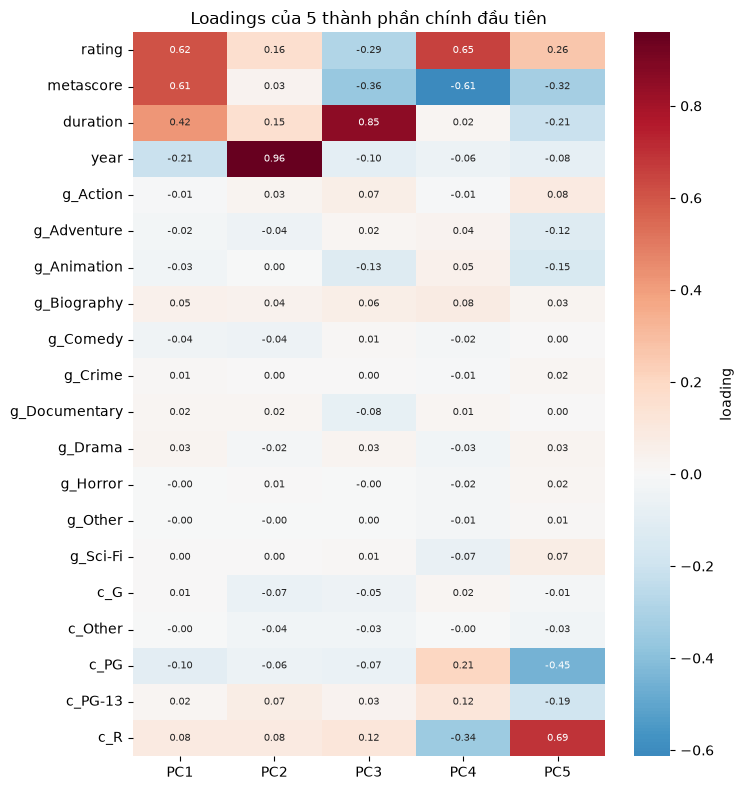

PC1 (31.8%): rating (+0.62), metascore (+0.61), duration (+0.42), year (-0.21)
PC2 (17.7%): year (+0.96), rating (+0.16), duration (+0.15), c_R (+0.08)
PC3 (16.0%): duration (+0.85), metascore (-0.36), rating (-0.29), g_Animation (-0.13)
PC4 (8.7%): rating (+0.65), metascore (-0.61), c_R (-0.34), c_PG (+0.21)


In [29]:
pca = PCA(n_components=N_PC, random_state=SEED).fit(X)
Z = pca.transform(X)
pc_names = [f'PC{i+1}' for i in range(N_PC)]
load = pd.DataFrame(pca.components_.T, index=feature_names, columns=pc_names)

top = load.iloc[:, :5]
fig, ax = plt.subplots(figsize=(7.5, 8))
sns.heatmap(top, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, cbar_kws={'label': 'loading'}, ax=ax)
ax.set_title('Loadings của 5 thành phần chính đầu tiên'); plt.tight_layout(); savefig('05_pca_loadings.png'); plt.show()
for c in pc_names[:4]:
    s = load[c].abs().sort_values(ascending=False).head(4).index
    print(c, f'({pca.explained_variance_ratio_[pc_names.index(c)]:.1%}):', ', '.join(f'{i} ({load.loc[i, c]:+.2f})' for i in s))

## 5. Chọn số cụm K – Elbow và Silhouette
Quét K = 2 … 10 trên **không gian PCA** (phương án chính) và trên **không gian đầy đủ** (để đối chiếu). Điểm khuỷu được xác định tự động bằng khoảng cách lớn nhất từ đường nối hai đầu mút của đường cong inertia.

In [30]:
K_RANGE = range(2, 11)
def sweep(M):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(M)
        rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(M, km.labels_),
                     'davies_bouldin': davies_bouldin_score(M, km.labels_),
                     'calinski_harabasz': calinski_harabasz_score(M, km.labels_)})
    return pd.DataFrame(rows).set_index('k')

def elbow_point(ks, inertia):
    x = (ks - ks.min()) / (ks.max() - ks.min()); y = (inertia - inertia.min()) / (inertia.max() - inertia.min())
    d = np.abs(y + x - 1) / np.sqrt(2)      # khoảng cách tới đường chéo nối hai đầu mút
    return int(ks[np.argmax(d)])

sw_pca = sweep(Z); sw_full = sweep(X.values)
ks = sw_pca.index.values
print('Không gian PCA:'); display(sw_pca.round(3))
print('Không gian đầy đủ:'); display(sw_full.round(3))
k_elbow = elbow_point(ks, sw_pca['inertia'].values)
k_sil = int(sw_pca['silhouette'].idxmax())
K = k_sil if abs(k_sil - k_elbow) <= 1 else k_elbow
if K == 2: K = int(sw_pca.loc[3:8, 'silhouette'].idxmax())
print(f'Elbow gợi ý K = {k_elbow} | Silhouette cao nhất tại K = {k_sil}')

Không gian PCA:


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,14992.281,0.175,1.859,938.575
3,12816.962,0.190,1.640,864.044
4,11524.009,0.192,1.548,779.394
5,10373.644,0.170,1.587,752.121
6,9632.243,0.170,1.519,704.979
7,9057.842,0.171,1.512,663.793
8,8586.879,0.167,1.533,629.076
9,8221.683,0.165,1.564,595.330
10,7906.550,0.170,1.571,566.547


Không gian đầy đủ:


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,16914.741,0.158,2.000,832.087
3,14738.940,0.168,1.782,751.544
4,13442.939,0.168,1.692,668.535
5,12288.201,0.145,1.755,635.600
6,11541.614,0.146,1.684,589.250
7,10965.119,0.143,1.682,549.236
8,10490.038,0.139,1.707,515.965
9,10112.612,0.138,1.741,485.497
10,9792.943,0.140,1.747,458.971


Elbow gợi ý K = 5 | Silhouette cao nhất tại K = 4


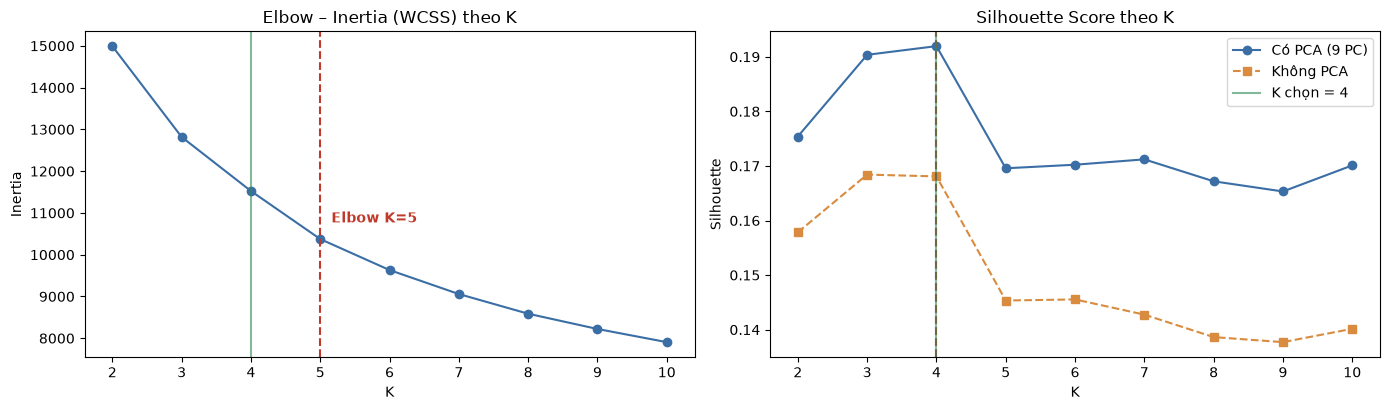

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(ks, sw_pca['inertia'], 'o-', color='#3b6ea5', label='Có PCA')
ax[0].axvline(k_elbow, ls='--', color='#c0392b'); ax[0].axvline(K, ls='-', color='#2e8b57', alpha=.6); ax[0].annotate(f'Elbow K={k_elbow}', (k_elbow, sw_pca.loc[k_elbow, 'inertia']), xytext=(8, 12), textcoords='offset points', color='#c0392b', fontweight='bold')
ax[0].set_title('Elbow – Inertia (WCSS) theo K'); ax[0].set_xlabel('K'); ax[0].set_ylabel('Inertia')
ax[1].plot(ks, sw_pca['silhouette'], 'o-', color='#3b6ea5', label=f'Có PCA ({N_PC} PC)')
ax[1].plot(ks, sw_full['silhouette'], 's--', color='#d98c3f', label='Không PCA')
ax[1].axvline(k_sil, ls='--', color='#c0392b'); ax[1].axvline(K, ls='-', color='#2e8b57', alpha=.6, label=f'K chọn = {K}'); ax[1].set_title('Silhouette Score theo K'); ax[1].set_xlabel('K'); ax[1].set_ylabel('Silhouette'); ax[1].legend()
plt.tight_layout(); savefig('06_elbow_silhouette.png'); plt.show()

In [32]:
# Quyết định K: ưu tiên Silhouette, có xét điểm khuỷu và khả năng diễn giải (không quá nhiều cụm nhỏ)
print(sw_pca[['silhouette']].assign(is_elbow=lambda d: d.index == k_elbow).round(3).T.to_string())
K = k_sil if abs(k_sil - k_elbow) <= 1 else k_elbow
# Nếu Silhouette cao nhất ở K quá nhỏ (=2) thì chọn K có Silhouette cao nhất trong 3..8 để phân nhóm có ý nghĩa hơn
if K == 2:
    K = int(sw_pca.loc[3:8, 'silhouette'].idxmax())
print(f'==> K được chọn = {K}  (Elbow = {k_elbow}, Silhouette tốt nhất = {k_sil})')

k              2      3      4     5      6      7      8      9      10
silhouette  0.175   0.19  0.192  0.17   0.17  0.171  0.167  0.165   0.17
is_elbow    False  False  False  True  False  False  False  False  False
==> K được chọn = 4  (Elbow = 5, Silhouette tốt nhất = 4)


## 6. K-Means: có PCA vs không có PCA
Hai phương án dùng cùng K, cùng `n_init = 20`, cùng seed. Vì Silhouette tính trên hai không gian khác nhau không so trực tiếp được, mọi nhãn cụm còn được **chấm lại trên cùng một không gian** (không gian đầy đủ đã chuẩn hóa) để so sánh công bằng.

In [33]:
def fit_time(M, reps=5):
    ts = []
    for r in range(reps):
        t0 = time.perf_counter(); m = KMeans(n_clusters=K, n_init=20, random_state=SEED + r).fit(M); ts.append(time.perf_counter() - t0)
    return float(np.mean(ts))

km_pca = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
km_full = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X.values)
lab_pca, lab_full = km_pca.labels_, km_full.labels_

def stability(M, reps=10):
    base = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(M).labels_
    return float(np.mean([adjusted_rand_score(base, KMeans(n_clusters=K, n_init=1, random_state=s).fit(M).labels_) for s in range(100, 100 + reps)]))

rows = []
for name, M, lab in (('Có PCA', Z, lab_pca), ('Không PCA', X.values, lab_full)):
    rows.append({'Phương án': name, 'Số chiều': M.shape[1],
                 'Silhouette (không gian riêng)': silhouette_score(M, lab),
                 'Silhouette (trên không gian đầy đủ)': silhouette_score(X.values, lab),
                 'Davies-Bouldin (↓)': davies_bouldin_score(M, lab),
                 'Calinski-Harabasz (↑)': calinski_harabasz_score(M, lab),
                 'Thời gian fit (s)': fit_time(M), 'Ổn định ARI (↑)': stability(M)})
cmp = pd.DataFrame(rows).set_index('Phương án')
ari_between = adjusted_rand_score(lab_pca, lab_full)
print(f'ARI giữa hai kết quả phân cụm = {ari_between:.3f}   (1 = giống hệt)')
cmp.round(3).T

ARI giữa hai kết quả phân cụm = 0.988   (1 = giống hệt)


Phương án,Có PCA,Không PCA
Số chiều,9.000,20.000
Silhouette (không gian riêng),0.192,0.168
Silhouette (trên không gian đầy đủ),0.168,0.168
Davies-Bouldin (↓),1.548,1.692
Calinski-Harabasz (↑),779.394,668.535
Thời gian fit (s),0.133,0.198
Ổn định ARI (↑),0.565,0.598


Có PCA        0    1    2     3
Không PCA                      
0          1096    0    0     0
1             3    0    3  1722
2             0  323    0     8
3             3    0  560     0


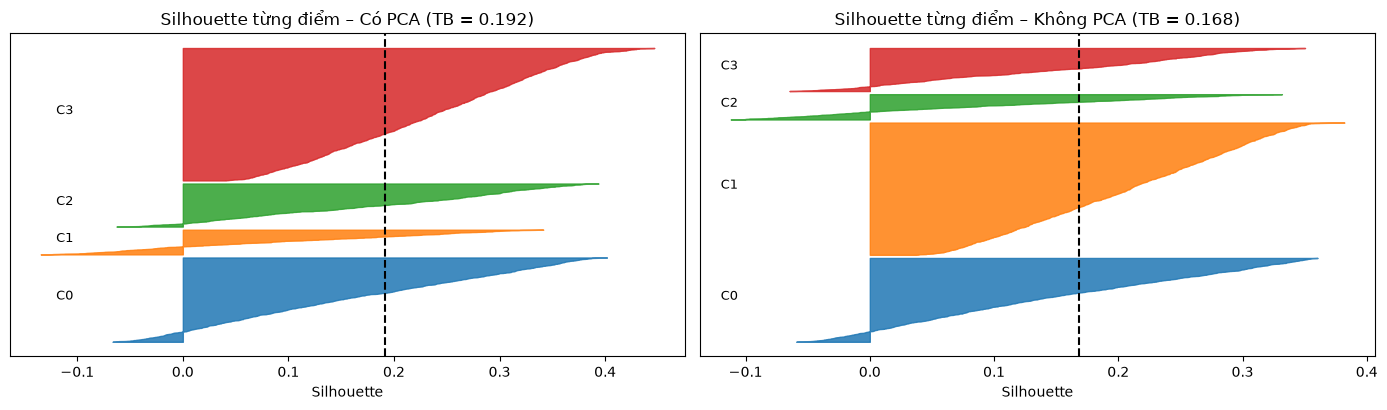

In [34]:
# Kích thước cụm và ánh xạ giữa hai phương án
ct = pd.crosstab(pd.Series(lab_full, name='Không PCA'), pd.Series(lab_pca, name='Có PCA'))
print(ct.to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, (name, M, lab) in zip(ax, (('Có PCA', Z, lab_pca), ('Không PCA', X.values, lab_full))):
    s = silhouette_samples(M, lab); y0 = 0
    for c in range(K):
        v = np.sort(s[lab == c]); a.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=.85, color=sns.color_palette('tab10')[c]); a.text(-0.12, y0 + len(v)/2, f'C{c}', fontsize=9); y0 += len(v) + 40
    a.axvline(s.mean(), ls='--', color='k'); a.set_title(f'Silhouette từng điểm – {name} (TB = {s.mean():.3f})'); a.set_xlabel('Silhouette'); a.set_yticks([])
plt.tight_layout(); savefig('07_silhouette_tung_cum.png'); plt.show()

## 7. Biểu đồ cụm trên mặt phẳng PC1 – PC2

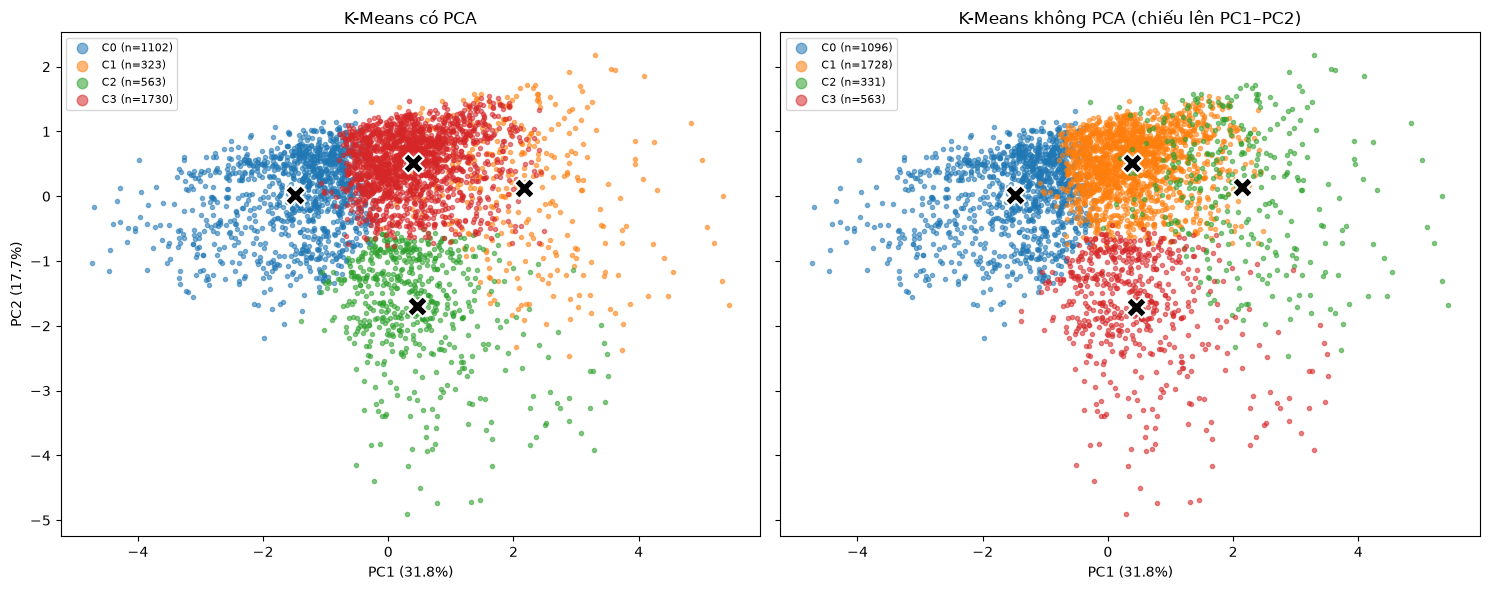

In [35]:
pal = sns.color_palette('tab10', K)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for a, (title, lab, cen) in zip(ax, (('K-Means có PCA', lab_pca, km_pca.cluster_centers_[:, :2]),
                                     ('K-Means không PCA (chiếu lên PC1–PC2)', lab_full, pca.transform(km_full.cluster_centers_)[:, :2]))):
    for c in range(K):
        m = lab == c; a.scatter(Z[m, 0], Z[m, 1], s=9, alpha=.55, color=pal[c], label=f'C{c} (n={m.sum()})')
    a.scatter(cen[:, 0], cen[:, 1], marker='X', s=220, c='k', edgecolor='w', lw=1.5, zorder=5)
    a.set_title(title); a.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})'); a.legend(markerscale=2.5, fontsize=8)
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.tight_layout(); savefig('08_cum_pc1_pc2.png'); plt.show()

## 8. Hồ sơ từng cụm – đặc điểm các nhóm phim
Phân tích trên nhãn của **K-Means có PCA** (phương án được chọn nếu chất lượng tương đương, vì nhanh hơn và ổn định hơn).

In [36]:
df['cluster'] = lab_pca
df['PC1'], df['PC2'] = Z[:, 0], Z[:, 1]
prof = df.groupby('cluster').agg(n=('title' if 'title' in df else 'Title', 'size'), rating=('rating', 'mean'), metascore=('metascore', 'mean'),
                                 duration=('duration', 'mean'), year=('year', 'mean'),
                                 year_min=('year', 'min'), year_max=('year', 'max'))
prof['pct'] = prof['n'] / prof['n'].sum() * 100
topg = df.groupby('cluster')['genre_grp'].agg(lambda s: ', '.join(f'{g} {v:.0%}' for g, v in s.value_counts(normalize=True).head(3).items()))
topc = df.groupby('cluster')['cert_grp'].agg(lambda s: ', '.join(f'{g} {v:.0%}' for g, v in s.value_counts(normalize=True).head(2).items()))
prof['top_genre'] = topg; prof['top_cert'] = topc
display(prof.round(2))

,n,rating,metascore,duration,year,year_min,year_max,pct,top_genre,top_cert
cluster,,,,,,,,,,
0,1102,5.92,51.08,102.23,2009.99,1977,2024,29.64,"Action 19%, Comedy 19%, Animation 18%","PG 45%, R 26%"
1,323,7.70,74.22,155.37,1996.98,1943,2024,8.69,"Biography 34%, Drama 22%, Action 20%","R 47%, PG-13 26%"
2,563,6.78,66.54,108.20,1974.03,1917,1995,15.14,"Drama 18%, Comedy 15%, Biography 14%","R 44%, PG 24%"
3,1730,7.12,68.21,110.25,2012.19,1988,2025,46.53,"Biography 21%, Action 14%, Animation 14%","R 58%, PG-13 18%"


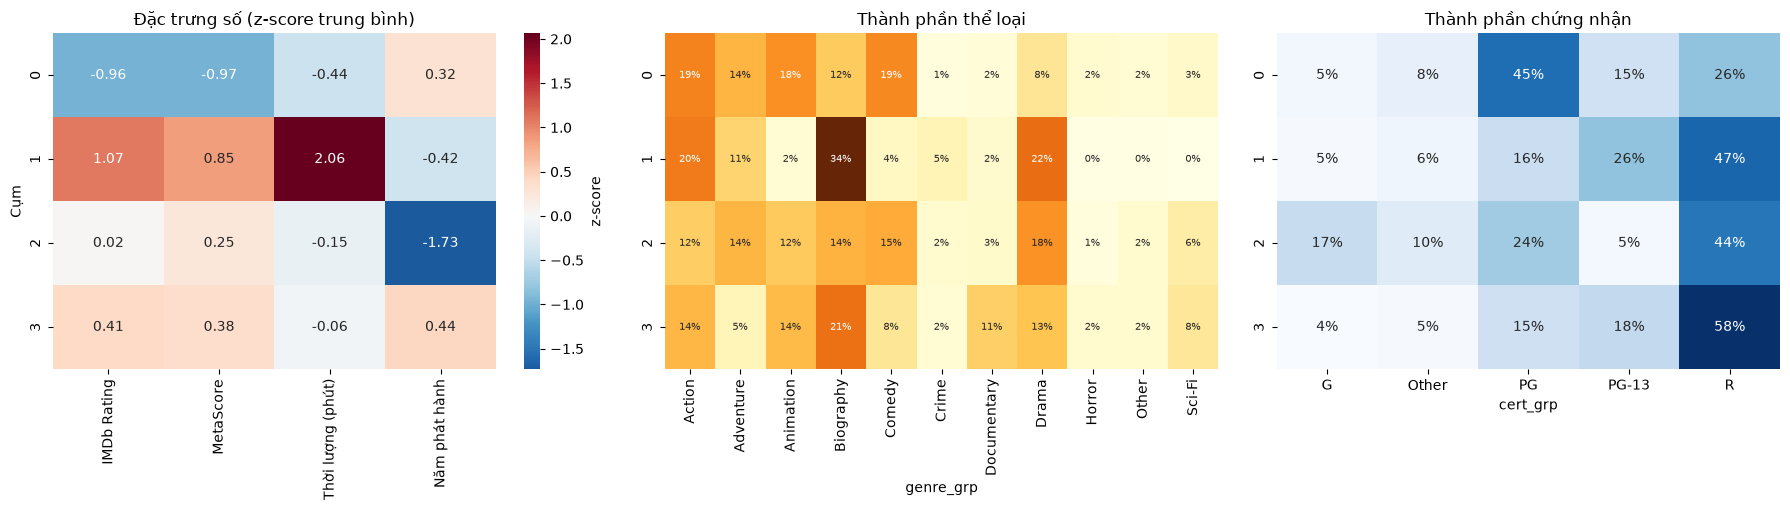

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={'width_ratios': [1.1, 1.1, 1]})
zmean = pd.DataFrame(scaler.transform(df[num_cols]), columns=num_cols).groupby(df['cluster']).mean()
zmean.columns = [labels_vi[c] for c in zmean.columns]
sns.heatmap(zmean, cmap='RdBu_r', center=0, annot=True, fmt='.2f', ax=ax[0], cbar_kws={'label': 'z-score'}); ax[0].set_title('Đặc trưng số (z-score trung bình)'); ax[0].set_ylabel('Cụm')
gc = pd.crosstab(df['cluster'], df['genre_grp'], normalize='index'); sns.heatmap(gc, cmap='YlOrBr', annot=True, fmt='.0%', annot_kws={'size': 7}, ax=ax[1], cbar=False); ax[1].set_title('Thành phần thể loại'); ax[1].set_ylabel('')
cc = pd.crosstab(df['cluster'], df['cert_grp'], normalize='index'); sns.heatmap(cc, cmap='Blues', annot=True, fmt='.0%', ax=ax[2], cbar=False); ax[2].set_title('Thành phần chứng nhận'); ax[2].set_ylabel('')
plt.tight_layout(); savefig('09_ho_so_cum.png'); plt.show()

In [38]:
# Phim tiêu biểu: gần tâm cụm nhất (trong không gian PCA)
dist = np.linalg.norm(Z - km_pca.cluster_centers_[lab_pca], axis=1)
df['dist_to_centroid'] = dist
reps = (df.sort_values('dist_to_centroid').groupby('cluster').head(5)
          .sort_values(['cluster', 'dist_to_centroid'])[['cluster', 'Title', 'year', 'genre', 'rating', 'duration']])
for c, g in reps.groupby('cluster'):
    print(f'Cụm {c}: ' + ' | '.join(f'{r.Title} ({r.year}, {r.genre}, {r.rating})' for r in g.itertuples()))

Cụm 0: Ice Princess (2005, Comedy, 6.0) | Inkheart (2008, Adventure, 6.1) | The Santa Clause 2 (2002, Comedy, 5.7) | Nim's Island (2008, Adventure, 6.0) | Noelle (2019, Comedy, 6.3)
Cụm 1: Into the Wild (2007, Adventure, 8.1) | The Hurricane (1999, Biography, 7.6) | The Talented Mr. Ripley (1999, Crime, 7.4) | Harry Potter and the Goblet of Fire (2005, Adventure, 7.7) | American Gangster (2007, Biography, 7.8)
Cụm 2: Utu (1983, Adventure, 6.9) | El rayo desintegrador (1966, Adventure, 6.7) | Akce Bororo (1973, Sci-Fi, 6.8) | The World in the Year 2000 (1972, Sci-Fi, 6.9) | Povestea dragostei (1977, Fantasy, 6.5)
Cụm 3: Kilo Two Bravo (2014, Adventure, 7.1) | The Motherhood Archives (2013, Documentary, 7.2) | Chronicles of the Beyond (2009, Sci-Fi, 6.9) | Harvest Moon (2013, Adventure, 7.3) | Focus on Infinity (2014, Documentary, 6.9)


## 9. Đặt tên và diễn giải các nhóm
| Cụm | Tên nhóm | Đặc điểm nổi bật |
|---|---|---|
| 0 | **Giải trí đại chúng điểm thấp** | Rating thấp nhất (~5,9) và MetaScore ~51; phim gia đình/hài/hoạt hình/phiêu lưu, chứng nhận PG nhiều nhất (45 %), thời lượng ngắn (~102 phút), chủ yếu 2000–2020. |
| 1 | **Đại tác phẩm dài, điểm cao** | Rating cao nhất (~7,7), MetaScore ~74 và thời lượng dài nhất (~155 phút, z = +2,06); thiên về Biography/Drama/Action, chứng nhận R. Nhóm nhỏ nhất (~9 %). |
| 2 | **Phim cổ điển (trước 1996)** | Tách bạch bởi năm phát hành (1917–1995, trung bình ~1974, z = −1,73); chất lượng trung bình-khá, tỷ lệ chứng nhận G và `Other` (Approved/Not Rated…) cao hơn các nhóm khác. |
| 3 | **Phim hiện đại chất lượng khá** | Nhóm lớn nhất (~47 %): phim sau 1988 (trung bình ~2012), rating ~7,1, MetaScore ~68, thời lượng vừa phải (~110 phút), R chiếm 58 %, nhiều Biography/Documentary hơn nhóm 0. |

**Lưu ý:** Silhouette chỉ khoảng 0,19 nên ranh giới giữa các nhóm khá mờ (đặc biệt cụm 0 và cụm 3 chồng lấn nhau); các nhóm nên được hiểu là *xu hướng* chứ không phải loại phim tách biệt tuyệt đối.

In [39]:
# Tên diễn giải có sẵn cho 4 cụm; nếu thuật toán chọn K khác 4 thì bổ sung tên mặc định.
CLUSTER_NAMES = {
    0: 'Giải trí đại chúng điểm thấp',
    1: 'Đại tác phẩm dài, điểm cao',
    2: 'Phim cổ điển (trước 1996)',
    3: 'Phim hiện đại chất lượng khá'
}
for c in range(K):
    CLUSTER_NAMES.setdefault(c, f'Nhóm phim {c}')


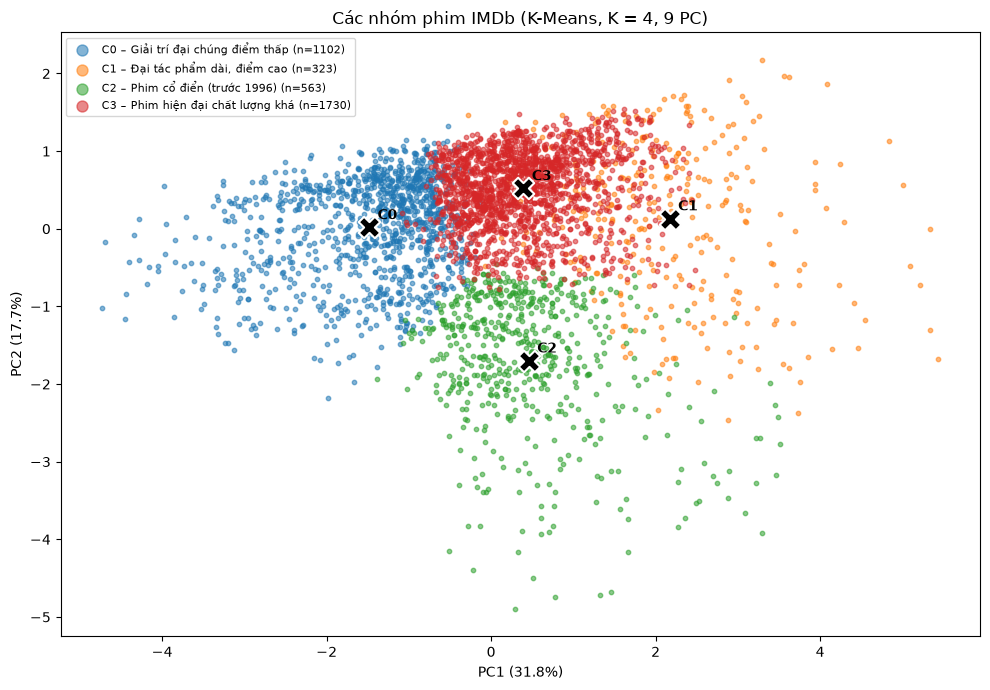

In [40]:
df['cluster_name'] = df['cluster'].map(CLUSTER_NAMES)
fig, ax = plt.subplots(figsize=(10, 7))
for c in range(K):
    m = df['cluster'] == c; ax.scatter(df.loc[m, 'PC1'], df.loc[m, 'PC2'], s=10, alpha=.55, color=pal[c], label=f'C{c} – {CLUSTER_NAMES[c]} (n={m.sum()})')
ax.scatter(km_pca.cluster_centers_[:, 0], km_pca.cluster_centers_[:, 1], marker='X', s=240, c='k', edgecolor='w', lw=1.5, zorder=5)
for c in range(K): ax.annotate(f'C{c}', km_pca.cluster_centers_[c, :2], xytext=(6, 6), textcoords='offset points', fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title(f'Các nhóm phim IMDb (K-Means, K = {K}, {N_PC} PC)'); ax.legend(markerscale=2.5, fontsize=8, loc='best')
plt.tight_layout(); savefig('10_cum_co_ten.png'); plt.show()

## 10. Lưu mô hình và kết quả
Lưu vào `models/clustering/`: scaler, PCA, hai mô hình K-Means, bảng gán cụm, bảng hồ sơ cụm và bảng so sánh.

In [41]:
joblib.dump({'scaler': scaler, 'num_cols': num_cols, 'feature_names': feature_names, 'cat_cols': cat_cols,
             'genre_keep': list(keep), 'cert_map': cert_map}, os.path.join(OUT_DIR, 'preprocessing.joblib'))
joblib.dump(pca, os.path.join(OUT_DIR, 'pca.joblib'))
joblib.dump(km_pca, os.path.join(OUT_DIR, 'kmeans_with_pca.joblib'))
joblib.dump(km_full, os.path.join(OUT_DIR, 'kmeans_without_pca.joblib'))

out = df[['Title', 'year', 'genre', 'certificate', 'rating', 'metascore', 'duration', 'PC1', 'PC2', 'cluster', 'cluster_name']].copy()
out['cluster_no_pca'] = lab_full
out.to_csv(os.path.join(OUT_DIR, 'movie_clusters.csv'), index=False, encoding='utf-8-sig')
prof.assign(name=pd.Series(CLUSTER_NAMES)).to_csv(os.path.join(OUT_DIR, 'cluster_profiles.csv'), encoding='utf-8-sig')
cmp.to_csv(os.path.join(OUT_DIR, 'pca_vs_no_pca.csv'), encoding='utf-8-sig')
sw_pca.to_csv(os.path.join(OUT_DIR, 'k_selection_pca.csv')); sw_full.to_csv(os.path.join(OUT_DIR, 'k_selection_full.csv'))
pd.DataFrame({'pc': pc_names + [], 'explained_variance_ratio': pca.explained_variance_ratio_, 'cumulative': np.cumsum(pca.explained_variance_ratio_)}).to_csv(os.path.join(OUT_DIR, 'pca_variance.csv'), index=False)
load.to_csv(os.path.join(OUT_DIR, 'pca_loadings.csv'))
summary = {'n_movies': int(len(df)), 'n_features': int(X.shape[1]), 'n_pc': int(N_PC), 'variance_kept': float(cum[N_PC-1]),
           'k_elbow': int(k_elbow), 'k_silhouette': int(k_sil), 'k_chosen': int(K), 'ari_between': float(ari_between)}
json.dump(summary, open(os.path.join(OUT_DIR, 'summary.json'), 'w'), indent=2)

# kiểm tra: nạp lại mô hình và dự đoán một phim mới
pre = joblib.load(os.path.join(OUT_DIR, 'preprocessing.joblib')); p = joblib.load(os.path.join(OUT_DIR, 'pca.joblib')); m = joblib.load(os.path.join(OUT_DIR, 'kmeans_with_pca.joblib'))
x0 = X.iloc[[0]].copy(); x0[pre['num_cols']] = pre['scaler'].transform(df.loc[[0], pre['num_cols']])
print('Phim đầu tiên ->', m.predict(p.transform(x0))[0], '| nhãn đã lưu:', df.loc[0, 'cluster'])
print(os.listdir(OUT_DIR)); summary

Phim đầu tiên -> 1 | nhãn đã lưu: 1
['01_phan_phoi_so.png', '02_the_loai_chung_nhan.png', '03_tuong_quan.png', '04_pca_phuong_sai.png', '05_pca_loadings.png', '06_elbow_silhouette.png', '07_silhouette_tung_cum.png', '08_cum_pc1_pc2.png', '09_ho_so_cum.png', '10_cum_co_ten.png', 'cluster_profiles.csv', 'kmeans_without_pca.joblib', 'kmeans_with_pca.joblib', 'k_selection_full.csv', 'k_selection_pca.csv', 'movie_clusters.csv', 'pca.joblib', 'pca_loadings.csv', 'pca_variance.csv', 'pca_vs_no_pca.csv', 'preprocessing.joblib', 'summary.json']


{'n_movies': 3718,
 'n_features': 20,
 'n_pc': 9,
 'variance_kept': 0.9070955352107554,
 'k_elbow': 5,
 'k_silhouette': 4,
 'k_chosen': 4,
 'ari_between': 0.9880813567471741}

## 11. Kết luận
Xem các bảng ở mục 4–8: PCA giữ phần lớn phương sai với số chiều ít hơn đáng kể, K được chọn bằng Elbow + Silhouette, và so sánh K-Means có/không PCA được chấm trên cùng một không gian. Chi tiết diễn giải nằm trong báo cáo Word và slide đi kèm.